In [27]:
# import necessary libraries

import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score
)

In [13]:
# generate the initial data
np.random.seed(42)

n_samples = 1000
d = 2

mu_0 = np.array([-2.0, 0.0])
mu_1 = np.array([2.0, 0.0])

sigma = 1.0

# Initial labels
y = np.random.randint(0, 2, size=n_samples)

# Generate points according to their class
X = np.zeros((n_samples, d))

for i in range(n_samples):
    if y[i] == 0:
        X[i] = np.random.normal(mu_0, sigma, size=d)
    else:
        X[i] = np.random.normal(mu_1, sigma, size=d)

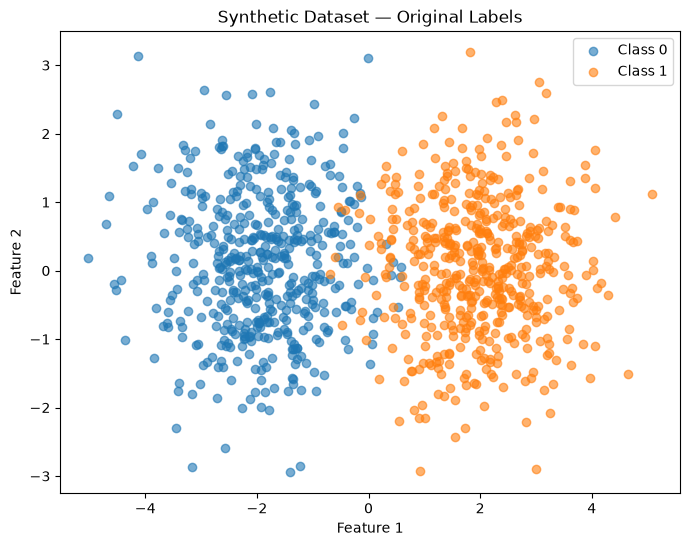

In [14]:
# visualize original labels

plt.figure(figsize=(8, 6))

plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Class 0",
    alpha=0.6
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Class 1",
    alpha=0.6
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Dataset — Original Labels")
plt.legend()
plt.show()

In [16]:
# construct KNN neighborhoods

k = 10

knn = NearestNeighbors(n_neighbors=k + 1)
knn.fit(X)

distances, indices = knn.kneighbors(X)

# Remove each point itself
neighbor_indices = indices[:, 1:]

In [ ]:
# calculate average neighbor label

neighbor_label_mean = y[neighbor_indices].mean(axis=1)
neighbor_label_mean[:10]

array([0. , 1. , 0. , 0. , 0. , 0.8, 0. , 0. , 0. , 1. ])

In [19]:
# apply label reassignment rule
epsilon = 0.1

y_modified = y.copy()
ambiguous = np.abs(neighbor_label_mean - 0.5) < epsilon
y_modified[ambiguous] = 1 - y_modified[ambiguous]

n_flipped = np.sum(y_modified != y)

print("Number of flipped labels:", n_flipped)
print("Percentage flipped:", 100 * n_flipped / n_samples)

Number of flipped labels: 22
Percentage flipped: 2.2


In [20]:
# create train-test split

# Use the modified labels
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_modified,
    test_size=0.2,
    random_state=42,
    stratify=y_modified
)

# Construct neighborhoods using all points
k = 10
knn = NearestNeighbors(n_neighbors=k + 1)
knn.fit(X)

_, neighbor_indices = knn.kneighbors(X)
neighbor_indices = neighbor_indices[:, 1:]

# Get the neighbor features for each point
X_neighbors = X[neighbor_indices]

# Map original point indices to the training and test sets
train_indices, test_indices = train_test_split(
    np.arange(len(X)),
    test_size=0.2,
    random_state=42,
    stratify=y_modified
)

X_center_train = torch.tensor(X[train_indices], dtype=torch.float32)
X_neighbors_train = torch.tensor(X_neighbors[train_indices], dtype=torch.float32)
y_train_tensor = torch.tensor(y_modified[train_indices], dtype=torch.float32)

X_center_test = torch.tensor(X[test_indices], dtype=torch.float32)
X_neighbors_test = torch.tensor(X_neighbors[test_indices], dtype=torch.float32)
y_test_tensor = torch.tensor(y_modified[test_indices], dtype=torch.float32)

print("Training centers:", X_center_train.shape)
print("Training neighborhoods:", X_neighbors_train.shape)
print("Test centers:", X_center_test.shape)
print("Test neighborhoods:", X_neighbors_test.shape)

Training centers: torch.Size([800, 2])
Training neighborhoods: torch.Size([800, 10, 2])
Test centers: torch.Size([200, 2])
Test neighborhoods: torch.Size([200, 10, 2])


In [22]:
# create deep sets class
class DeepSets(nn.Module):
    def __init__(self):
        super().__init__()

        self.phi = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Linear(32, 32)
        )

        self.rho = nn.Sequential(
            nn.Linear(34, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, center, neighbors):
        neighbor_features = self.phi(neighbors)
        pooled = neighbor_features.sum(dim=1)
        combined = torch.cat([center, pooled], dim=1)
        output = self.rho(combined)

        return output.squeeze(1)

In [23]:
# Initialize model and training setup
model = DeepSets()

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 50

# Train the model
for epoch in range(epochs):
    model.train()

    optimizer.zero_grad()

    outputs = model(X_center_train, X_neighbors_train)
    loss = criterion(outputs, y_train_tensor)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch + 1}/{epochs}], Loss: {loss.item():.4f}")

Epoch [10/50], Loss: 0.3303
Epoch [20/50], Loss: 0.1305
Epoch [30/50], Loss: 0.0822
Epoch [40/50], Loss: 0.0707
Epoch [50/50], Loss: 0.0669


In [24]:
# check baseline performance
model.eval()

with torch.no_grad():
    logits = model(X_center_test, X_neighbors_test)
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= 0.5).int()

accuracy = accuracy_score(
    y_test_tensor.numpy(),
    predictions.numpy()
)

macro_f1 = f1_score(
    y_test_tensor.numpy(),
    predictions.numpy(),
    average="macro"
)

print(f"Baseline accuracy: {accuracy:.4f}")
print(f"Baseline macro-F1: {macro_f1:.4f}")

Baseline accuracy: 0.9750
Baseline macro-F1: 0.9750


In [25]:
# local neighborhood sensitivity

model.eval()

# Use 50 test samples
n_explain = 50
center_samples = X_center_test[:n_explain]
neighbor_samples = X_neighbors_test[:n_explain]

# Original predicted probabilities
with torch.no_grad():
    original_logits = model(center_samples, neighbor_samples)
    original_probs = torch.sigmoid(original_logits)

probability_changes = []

# Candidate points from each class
class_0_points = X[y_modified == 0]
class_1_points = X[y_modified == 1]

for i in range(n_explain):
    for j in range(k):
        modified_neighbors = neighbor_samples[i:i+1].clone()

        # Identify the class of the neighbor being replaced.
        original_neighbor = modified_neighbors[0, j].numpy()
        distances_to_points = np.linalg.norm(X - original_neighbor, axis=1)
        nearest_index = np.argmin(distances_to_points)
        original_class = y_modified[nearest_index]

        # Choose a replacement from the opposite class.
        candidates = class_1_points if original_class == 0 else class_0_points
        replacement_index = np.random.randint(len(candidates))
        replacement = candidates[replacement_index]

        modified_neighbors[0, j] = torch.tensor(
            replacement, dtype=torch.float32
        )

        # Measure the change in predicted probability.
        with torch.no_grad():
            modified_logit = model(
                center_samples[i:i+1], modified_neighbors
            )
            modified_prob = torch.sigmoid(modified_logit).item()

        change = abs(original_probs[i].item() - modified_prob)
        probability_changes.append(change)

# Summarize sensitivity
mean_change = np.mean(probability_changes)
max_change = np.max(probability_changes)

print(f"Samples analyzed: {n_explain}")
print(f"Single-neighbor replacements: {len(probability_changes)}")
print(f"Mean absolute probability change: {mean_change:.4f}")
print(f"Maximum absolute probability change: {max_change:.4f}")

Samples analyzed: 50
Single-neighbor replacements: 500
Mean absolute probability change: 0.0212
Maximum absolute probability change: 0.3850
